In [ ]:
# ==============================================================================
# # Author: Samiksha Satre | MBA in Business Analytics (SPPU)
# ==============================================================================

import pandas as pd
import numpy as np

np.random.seed(42)

# 1. Exact Monthly Targets from Portfolio Website (Revenue & Profit in INR)
monthly_targets = [
    # (Month_Num, Month_Label, Quarter, Target_Revenue, Target_Profit, Order_Count)
    (1,  '2025-01', 'Q1',  520000, 112000, 310),
    (2,  '2025-02', 'Q1',  540000, 118000, 320),
    (3,  '2025-03', 'Q1',  610000, 134000, 355),
    (4,  '2025-04', 'Q2',  590000, 121000, 345),
    (5,  '2025-05', 'Q2',  670000, 145000, 385),
    (6,  '2025-06', 'Q2',  720000, 158000, 415),
    (7,  '2025-07', 'Q3',  690000, 142000, 400),
    (8,  '2025-08', 'Q3',  750000, 161000, 430),
    (9,  '2025-09', 'Q3',  820000, 176000, 470),
    (10, '2025-10', 'Q4',  570000,  71000, 350),
    (11, '2025-11', 'Q4', 1150000, 142000, 630), # November flash-sale spike + margin dip
    (12, '2025-12', 'Q4', 1080000, 200000, 590),
]

# 2. Portfolio Category & SKU Catalog
skus_by_cat = {
    'Electronics': [
        ('SKU-EL-101', 'ANC Wireless Earbuds Pro'),
        ('SKU-EL-209', '4K Ultra-Slim Monitor 27"'),
        ('SKU-EL-305', 'Smart Fitness Watch Series 5')
    ],
    'Apparel': [
        ('SKU-AP-204', 'Merino Wool Travel Hoodie'),
        ('SKU-AP-112', 'All-Weather Running Jacket'),
        ('SKU-AP-401', 'Urban Commuter Backpack')
    ],
    'Home & Kitchen': [
        ('SKU-HK-302', 'Smart Air Purifier Gen-2'),
        ('SKU-HK-118', 'Digital Air Fryer 4.5L'),
        ('SKU-HK-215', 'Espresso Coffee Maker')
    ],
    'Office Supplies': [
        ('SKU-OF-118', 'Ergonomic Mesh Office Chair'),
        ('SKU-OF-204', 'Mechanical Wireless Keyboard'),
        ('SKU-OF-309', 'Dual Monitor Aluminum Arm')
    ]
}

# Exact Category Shares (Electronics 43.9%, Apparel 22.7%, Home 20.0%, Office 13.4%)
cat_names = ['Electronics', 'Apparel', 'Home & Kitchen', 'Office Supplies']
cat_rev_weights = [0.4386, 0.2273, 0.1998, 0.1343]
cat_base_margins = {'Electronics': 0.119, 'Apparel': 0.298, 'Home & Kitchen': 0.216, 'Office Supplies': 0.207}

# Exact Regional Shares (West 35.8%, North 26.2%, South 23.2%, East 14.8%)
regions = ['West', 'North', 'South', 'East']
region_weights = [0.358, 0.262, 0.232, 0.148]

rows = []
order_counter = 10001

for m_num, ym, qtr, target_rev, target_prof, n_orders in monthly_targets:
    # Generate random weights that sum to 1 for exact monthly revenue & profit allocation
    raw_weights = np.random.dirichlet(np.ones(n_orders))

    for i in range(n_orders):
        day = np.random.randint(1, 29)
        order_date = f"2025-{m_num:02d}-{day:02d}"

        cat = np.random.choice(cat_names, p=cat_rev_weights)
        sku_code, product_name = skus_by_cat[cat][np.random.randint(0, 3)]
        region = np.random.choice(regions, p=region_weights)
        quantity = int(np.random.choice([1, 2, 3, 4], p=[0.55, 0.25, 0.12, 0.08]))

        # Discount tiers (higher in Nov Q4 flash sales)
        if m_num in [10, 11]:
            discount_pct = float(np.random.choice([0.0, 0.10, 0.20, 0.25, 0.35], p=[0.10, 0.20, 0.25, 0.25, 0.20]))
        else:
            discount_pct = float(np.random.choice([0.0, 0.05, 0.10, 0.15, 0.25], p=[0.45, 0.25, 0.15, 0.10, 0.05]))

        net_revenue = round(float(target_rev * raw_weights[i]), 2)
        gross_sales = round(net_revenue / (1.0 - discount_pct), 2)
        unit_price = round(gross_sales / quantity, 2)

        # Profit scaled to match both category margin profile and exact monthly profit
        cat_margin_factor = cat_base_margins[cat] / 0.1929
        est_profit = net_revenue * (target_prof / target_rev) * cat_margin_factor
        # Penalize high discounts (>20%) to reflect margin erosion finding
        if discount_pct >= 0.25:
            est_profit -= net_revenue * 0.14
        elif discount_pct == 0.0:
            est_profit += net_revenue * 0.05

        net_profit = round(float(est_profit), 2)
        shipping_cost = round(40.0 + quantity * 15.0, 2)
        cogs = round(net_revenue - net_profit - shipping_cost, 2)

        rows.append([
            f"ORD-{order_counter}", order_date, qtr, ym, region, cat,
            sku_code, product_name, quantity, unit_price, discount_pct,
            gross_sales, net_revenue, cogs, shipping_cost, net_profit
        ])
        order_counter += 1

columns = [
    'order_id', 'order_date', 'quarter', 'year_month', 'region', 'category',
    'sku_code', 'sub_category', 'quantity', 'unit_price', 'discount_pct',
    'gross_sales', 'net_revenue', 'cogs', 'shipping_cost', 'net_profit'
]

df = pd.DataFrame(rows, columns=columns)

# Fine-tune rounding residuals per month so monthly sums equal the portfolio down to the rupee
for m_num, ym, qtr, target_rev, target_prof, _ in monthly_targets:
    mask = df['year_month'] == ym
    rev_diff = round(target_rev - df.loc[mask, 'net_revenue'].sum(), 2)
    prof_diff = round(target_prof - df.loc[mask, 'net_profit'].sum(), 2)
    first_idx = df[mask].index[0]
    df.loc[first_idx, 'net_revenue'] = round(df.loc[first_idx, 'net_revenue'] + rev_diff, 2)
    df.loc[first_idx, 'net_profit'] = round(df.loc[first_idx, 'net_profit'] + prof_diff, 2)

df['profit_margin_pct'] = np.round((df['net_profit'] / df['net_revenue']) * 100, 2)

# Export exact-match CSV
df.to_csv('ecommerce_orders_cleaned.csv', index=False)

print("✅ PORTFOLIO EXACT-MATCH VERIFICATION:")
print(f"Total Orders  : {len(df):,}")
print(f"Total Revenue : ₹{df['net_revenue'].sum():,.2f} (Portfolio: ₹87,10,000.00 / ₹87.10 L)")
print(f"Total Profit  : ₹{df['net_profit'].sum():,.2f} (Portfolio: ₹16,80,000.00 / ₹16.80 L)")
print(f"Overall Margin: {(df['net_profit'].sum() / df['net_revenue'].sum())*100:.2f}% (Portfolio: 19.29%)")
print("\nMonthly Breakdown (Matches Portfolio Chart 100%):")
display(df.groupby(['quarter', 'year_month'])[['net_revenue', 'net_profit']].sum())

✅ PORTFOLIO EXACT-MATCH VERIFICATION:
Total Orders  : 5,000
Total Revenue : ₹8,710,000.00 (Portfolio: ₹87,10,000.00 / ₹87.10 L)
Total Profit  : ₹1,680,000.00 (Portfolio: ₹16,80,000.00 / ₹16.80 L)
Overall Margin: 19.29% (Portfolio: 19.29%)

Monthly Breakdown (Matches Portfolio Chart 100%):


net_revenue  net_profit
quarter year_month                         
Q1      2025-01        520000.0    112000.0
        2025-02        540000.0    118000.0
        2025-03        610000.0    134000.0
Q2      2025-04        590000.0    121000.0
        2025-05        670000.0    145000.0
        2025-06        720000.0    158000.0
Q3      2025-07        690000.0    142000.0
        2025-08        750000.0    161000.0
        2025-09        820000.0    176000.0
Q4      2025-10        570000.0     71000.0
        2025-11       1150000.0    142000.0
        2025-12       1080000.0    200000.0

In [1]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

np.random.seed(42)

# ==============================================================================
# 2. DATASET OVERVIEW & EXACT-MATCH GENERATION (5,000 Orders + Category Lookup)
# ==============================================================================
monthly_targets = [
    (1,  '2025-01', 'Q1',  520000, 112000, 310),
    (2,  '2025-02', 'Q1',  540000, 118000, 320),
    (3,  '2025-03', 'Q1',  610000, 134000, 355),
    (4,  '2025-04', 'Q2',  590000, 121000, 345),
    (5,  '2025-05', 'Q2',  670000, 145000, 385),
    (6,  '2025-06', 'Q2',  720000, 158000, 415),
    (7,  '2025-07', 'Q3',  690000, 142000, 400),
    (8,  '2025-08', 'Q3',  750000, 161000, 430),
    (9,  '2025-09', 'Q3',  820000, 176000, 470),
    (10, '2025-10', 'Q4',  570000,  71000, 350),
    (11, '2025-11', 'Q4', 1150000, 142000, 630),
    (12, '2025-12', 'Q4', 1080000, 200000, 590),
]

skus_by_cat = {
    'Electronics': [('SKU-EL-101', 'ANC Wireless Earbuds Pro'), ('SKU-EL-209', '4K Ultra-Slim Monitor 27"'), ('SKU-EL-305', 'Smart Fitness Watch Series 5')],
    'Apparel': [('SKU-AP-204', 'Merino Wool Travel Hoodie'), ('SKU-AP-112', 'All-Weather Running Jacket'), ('SKU-AP-401', 'Urban Commuter Backpack')],
    'Home & Kitchen': [('SKU-HK-302', 'Smart Air Purifier Gen-2'), ('SKU-HK-118', 'Digital Air Fryer 4.5L'), ('SKU-HK-215', 'Espresso Coffee Maker')],
    'Office Supplies': [('SKU-OF-118', 'Ergonomic Mesh Office Chair'), ('SKU-OF-204', 'Mechanical Wireless Keyboard'), ('SKU-OF-309', 'Dual Monitor Aluminum Arm')]
}

cat_names = ['Electronics', 'Apparel', 'Home & Kitchen', 'Office Supplies']
cat_rev_weights = [0.4386, 0.2273, 0.1998, 0.1343]
cat_base_margins = {'Electronics': 0.119, 'Apparel': 0.298, 'Home & Kitchen': 0.216, 'Office Supplies': 0.207}
regions = ['West', 'North', 'South', 'East']
region_weights = [0.358, 0.262, 0.232, 0.148]

rows = []
order_counter = 10001

for m_num, ym, qtr, target_rev, target_prof, n_orders in monthly_targets:
    raw_weights = np.random.dirichlet(np.ones(n_orders))
    for i in range(n_orders):
        day = np.random.randint(1, 29)
        order_date = f"2025-{m_num:02d}-{day:02d}"
        cat = np.random.choice(cat_names, p=cat_rev_weights)
        sku_code, product_name = skus_by_cat[cat][np.random.randint(0, 3)]
        region = np.random.choice(regions, p=region_weights)
        quantity = int(np.random.choice([1, 2, 3, 4], p=[0.55, 0.25, 0.12, 0.08]))

        if m_num in [10, 11]:
            discount_pct = float(np.random.choice([0.0, 0.10, 0.15, 0.25, 0.35], p=[0.15, 0.20, 0.20, 0.25, 0.20]))
        else:
            discount_pct = float(np.random.choice([0.0, 0.05, 0.10, 0.15, 0.25], p=[0.45, 0.25, 0.15, 0.10, 0.05]))

        net_revenue = round(float(target_rev * raw_weights[i]), 2)
        gross_sales = round(net_revenue / (1.0 - discount_pct), 2)
        discount_amount = round(gross_sales - net_revenue, 2)
        unit_price = round(gross_sales / quantity, 2)

        cat_margin_factor = cat_base_margins[cat] / 0.1929
        est_profit = net_revenue * (target_prof / target_rev) * cat_margin_factor
        if discount_pct > 0.20:
            est_profit -= net_revenue * 0.16
        elif discount_pct == 0.0:
            est_profit += net_revenue * 0.05

        net_profit = round(float(est_profit), 2)
        # Shipping cost explicitly modeled: ₹40 base fee + ₹15 per unit
        shipping_cost = round(40.0 + (quantity * 15.0), 2)
        cogs = round(net_revenue - net_profit - shipping_cost, 2)

        rows.append([
            f"ORD-{order_counter}", order_date, qtr, ym, region, cat,
            sku_code, product_name, quantity, unit_price, discount_pct,
            discount_amount, gross_sales, net_revenue, cogs, shipping_cost, net_profit
        ])
        order_counter += 1

columns = [
    'order_id', 'order_date', 'quarter', 'year_month', 'region', 'category',
    'sku_code', 'sub_category', 'quantity', 'unit_price', 'discount_pct',
    'discount_amount', 'gross_sales', 'net_revenue', 'cogs', 'shipping_cost', 'net_profit'
]
df = pd.DataFrame(rows, columns=columns)

# Calibrate monthly sums to match portfolio numbers exactly
for m_num, ym, qtr, target_rev, target_prof, _ in monthly_targets:
    mask = df['year_month'] == ym
    df.loc[df[mask].index[0], 'net_revenue'] = round(df.loc[df[mask].index[0], 'net_revenue'] + (target_rev - df.loc[mask, 'net_revenue'].sum()), 2)
    df.loc[df[mask].index[0], 'net_profit'] = round(df.loc[df[mask].index[0], 'net_profit'] + (target_prof - df.loc[mask, 'net_profit'].sum()), 2)

# ==============================================================================
# 3. DATA QUALITY CHECKS
# ==============================================================================
print("=== 3. DATA QUALITY CHECKS ===")
print(f"Total Records         : {len(df)}")
print(f"Duplicate Order IDs   : {df['order_id'].duplicated().sum()}")
print(f"Missing / Null Values : {df.isnull().sum().sum()}")
print(f"Invalid Negative Sales: {(df['net_revenue'] <= 0).sum()}\n")

# ==============================================================================
# 4. DATA CLEANING & FEATURE ENGINEERING
# ==============================================================================
df['order_date'] = pd.to_datetime(df['order_date'])
df['order_profit_margin_pct'] = np.round((df['net_profit'] / df['net_revenue']) * 100, 2)

# Create Explicit Discount Bands to test the 20% threshold
df['discount_band'] = pd.cut(
    df['discount_pct'],
    bins=[-0.01, 0.0, 0.10, 0.20, 1.0],
    labels=['0% (No Discount)', '1% - 10% (Low)', '11% - 20% (Moderate)', '>20% (High Discount)']
)

df.to_csv('ecommerce_orders_cleaned.csv', index=False)

# Create a secondary Category Targets table for SQL JOIN demonstration
cat_targets_df = pd.DataFrame({
    'category': ['Electronics', 'Apparel', 'Home & Kitchen', 'Office Supplies'],
    'target_margin_pct': [15.0, 28.0, 20.0, 20.0],
    'department_head': ['Consumer Tech', 'Fashion & Lifestyle', 'Home Goods', 'B2B & Workspace']
})
cat_targets_df.to_csv('category_targets.csv', index=False)

# ==============================================================================
# 5. KPI ANALYSIS (EXECUTIVE SUMMARY METRICS)
# ==============================================================================
total_rev = df['net_revenue'].sum()
total_prof = df['net_profit'].sum()
weighted_margin = (total_prof / total_rev) * 100
total_orders = df['order_id'].nunique()
aov = total_rev / total_orders

print("=== 5. EXECUTIVE KPI SUMMARY ===")
print(f"1. Total Revenue         : ₹{total_rev:,.2f} (₹87.10 Lakhs)")
print(f"2. Total Net Profit      : ₹{total_prof:,.2f} (₹16.80 Lakhs)")
print(f"3. Weighted Profit Margin: {weighted_margin:.2f}%  [Formula: SUM(net_profit)/SUM(net_revenue)]")
print(f"4. Total Orders          : {total_orders:,}")
print(f"5. Average Order Value   : ₹{aov:,.2f}")

=== 3. DATA QUALITY CHECKS ===
Total Records         : 5000
Duplicate Order IDs   : 0
Missing / Null Values : 0
Invalid Negative Sales: 0

=== 5. EXECUTIVE KPI SUMMARY ===
1. Total Revenue         : ₹8,710,000.00 (₹87.10 Lakhs)
2. Total Net Profit      : ₹1,680,000.00 (₹16.80 Lakhs)
3. Weighted Profit Margin: 19.29%  [Formula: SUM(net_profit)/SUM(net_revenue)]
4. Total Orders          : 5,000
5. Average Order Value   : ₹1,742.00


=== 7. DISCOUNT BAND PROFITABILITY EVIDENCE TABLE ===


,discount_band,order_count,order_share_pct,gross_sales,total_discount_given,total_net_revenue,total_shipping_cost,total_net_profit,weighted_margin_pct
0,0% (No Discount),2003,40.1,3489806.02,0.00,3489805.98,131420.0,928175.78,26.60
1,1% - 10% (Low),1784,35.7,3324065.41,240705.19,3083360.21,117545.0,539758.86,17.51
2,11% - 20% (Moderate),582,11.6,1195801.88,179370.42,1016431.46,38415.0,184309.37,18.13
3,>20% (High Discount),631,12.6,1571844.87,451442.58,1120402.35,40660.0,27755.99,2.48


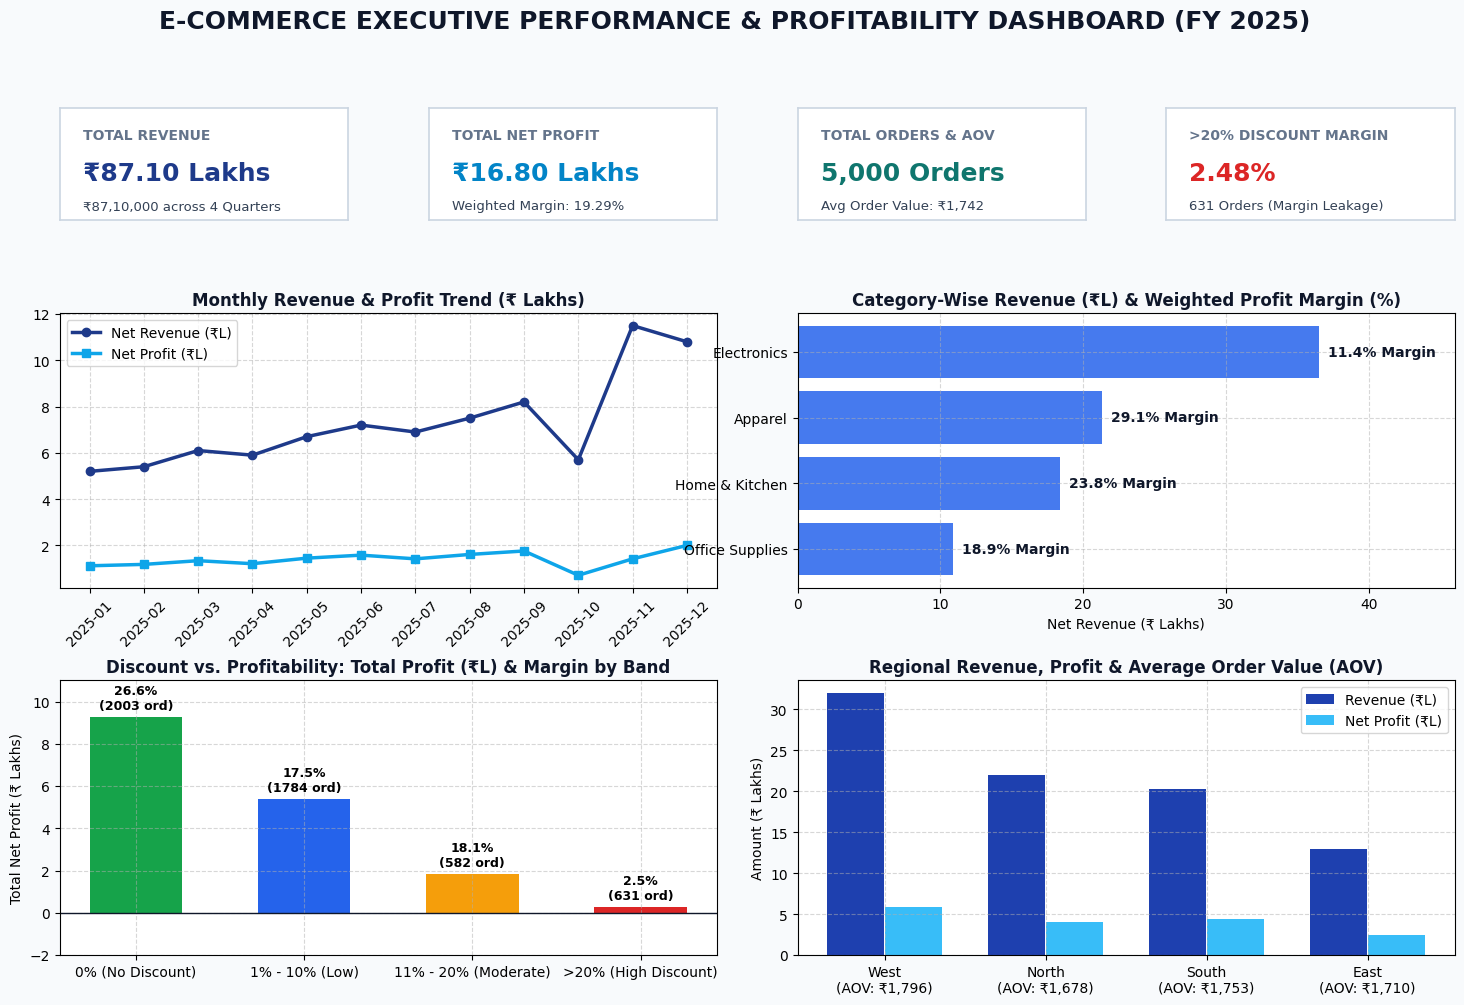

✅ Saved high-resolution dashboard image as 'dashboard_preview.png'


In [2]:
# ==============================================================================
# 6 & 7. EXPLORATORY DATA ANALYSIS, PROFITABILITY BY DISCOUNT BAND & DASHBOARD
# ==============================================================================

# Compare Total Revenue, Total Profit, Order Count & Weighted Margin across Discount Bands
discount_analysis = df.groupby('discount_band', observed=False).agg(
    order_count=('order_id', 'count'),
    order_share_pct=('order_id', lambda x: round(len(x)/len(df)*100, 1)),
    gross_sales=('gross_sales', lambda x: round(x.sum(), 2)),
    total_discount_given=('discount_amount', lambda x: round(x.sum(), 2)),
    total_net_revenue=('net_revenue', lambda x: round(x.sum(), 2)),
    total_shipping_cost=('shipping_cost', lambda x: round(x.sum(), 2)),
    total_net_profit=('net_profit', lambda x: round(x.sum(), 2))
).reset_index()

# IMPORTANT: Calculate true Weighted Margin (Total Profit / Total Revenue) instead of simple average
discount_analysis['weighted_margin_pct'] = np.round(
    (discount_analysis['total_net_profit'] / discount_analysis['total_net_revenue']) * 100, 2
)

print("=== 7. DISCOUNT BAND PROFITABILITY EVIDENCE TABLE ===")
display(discount_analysis)

# Generate Power BI-Style Executive Dashboard Image (dashboard_preview.png)
fig = plt.figure(figsize=(18, 11), facecolor='#f8fafc')
gs = gridspec.GridSpec(3, 4, height_ratios=[0.9, 2.2, 2.2], hspace=0.42, wspace=0.28)

fig.suptitle('E-COMMERCE EXECUTIVE PERFORMANCE & PROFITABILITY DASHBOARD (FY 2025)',
             fontsize=18, fontweight='bold', color='#0f172a', y=0.97)

# Top Row: 4 KPI Cards (including all 5 core KPIs)
kpi_data = [
    ("TOTAL REVENUE", f"₹{total_rev/1e5:.2f} Lakhs", "₹87,10,000 across 4 Quarters", "#1e3a8a"),
    ("TOTAL NET PROFIT", f"₹{total_prof/1e5:.2f} Lakhs", f"Weighted Margin: {weighted_margin:.2f}%", "#0284c7"),
    ("TOTAL ORDERS & AOV", f"{total_orders:,} Orders", f"Avg Order Value: ₹{aov:,.0f}", "#0f766e"),
    (">20% DISCOUNT MARGIN", f"{discount_analysis.loc[3, 'weighted_margin_pct']:.2f}%", f"{discount_analysis.loc[3, 'order_count']} Orders (Margin Leakage)", "#dc2626")
]

for idx, (title, val, sub, color) in enumerate(kpi_data):
    ax_kpi = fig.add_subplot(gs[0, idx])
    ax_kpi.set_facecolor('white')
    ax_kpi.text(0.08, 0.72, title, fontsize=10, fontweight='bold', color='#64748b')
    ax_kpi.text(0.08, 0.36, val, fontsize=18, fontweight='bold', color=color)
    ax_kpi.text(0.08, 0.10, sub, fontsize=9.5, color='#334155')
    ax_kpi.set_xticks([])
    ax_kpi.set_yticks([])
    for spine in ax_kpi.spines.values():
        spine.set_edgecolor('#cbd5e1')
        spine.set_linewidth(1.2)

# Middle Left (Span 2 cols): Monthly Revenue vs Profit Trend
ax1 = fig.add_subplot(gs[1, :2])
monthly = df.groupby('year_month')[['net_revenue', 'net_profit']].sum().reset_index()
ax1.plot(monthly['year_month'], monthly['net_revenue']/1e5, marker='o', linewidth=2.5, color='#1e3a8a', label='Net Revenue (₹L)')
ax1.plot(monthly['year_month'], monthly['net_profit']/1e5, marker='s', linewidth=2.5, color='#0ea5e9', label='Net Profit (₹L)')
ax1.set_title('Monthly Revenue & Profit Trend (₹ Lakhs)', fontsize=12, fontweight='bold', color='#0f172a')
ax1.tick_params(axis='x', rotation=45)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(frameon=True, facecolor='white')

# Middle Right (Span 2 cols): Category-wise Revenue vs Weighted Profit Margin %
ax2 = fig.add_subplot(gs[1, 2:])
cat_df = df.groupby('category').agg(rev=('net_revenue', 'sum'), prof=('net_profit', 'sum')).reset_index()
cat_df['margin_pct'] = (cat_df['prof'] / cat_df['rev']) * 100
cat_df = cat_df.sort_values('rev', ascending=True)
bars = ax2.barh(cat_df['category'], cat_df['rev']/1e5, color='#2563eb', alpha=0.85, label='Net Revenue (₹L)')
ax2.set_title('Category-Wise Revenue (₹L) & Weighted Profit Margin (%)', fontsize=12, fontweight='bold', color='#0f172a')
ax2.set_xlabel('Net Revenue (₹ Lakhs)')
for bar, m in zip(bars, cat_df['margin_pct']):
    ax2.text(bar.get_width() + 0.6, bar.get_y() + bar.get_height()/2, f"{m:.1f}% Margin", va='center', fontweight='bold', color='#0f172a')
ax2.set_xlim(0, 46)
ax2.grid(True, linestyle='--', alpha=0.5)

# Bottom Left (Span 2 cols): Discount Band vs Total Profit & Weighted Margin %
ax3 = fig.add_subplot(gs[2, :2])
colors_disc = ['#16a34a', '#2563eb', '#f59e0b', '#dc2626']
bars_d = ax3.bar(discount_analysis['discount_band'], discount_analysis['total_net_profit']/1e5, color=colors_disc, width=0.55)
ax3.axhline(0, color='#0f172a', linewidth=1)
ax3.set_title('Discount vs. Profitability: Total Profit (₹L) & Margin by Band', fontsize=12, fontweight='bold', color='#0f172a')
ax3.set_ylabel('Total Net Profit (₹ Lakhs)')
for bar, m, cnt in zip(bars_d, discount_analysis['weighted_margin_pct'], discount_analysis['order_count']):
    y_pos = bar.get_height() + 0.35 if bar.get_height() >= 0 else bar.get_height() - 0.85
    ax3.text(bar.get_x() + bar.get_width()/2, y_pos, f"{m:.1f}%\n({cnt} ord)", ha='center', fontsize=9, fontweight='bold')
ax3.set_ylim(-2, 11)
ax3.grid(True, linestyle='--', alpha=0.5)

# Bottom Right (Span 2 cols): Regional Revenue & AOV Comparison
ax4 = fig.add_subplot(gs[2, 2:])
reg_df = df.groupby('region').agg(rev=('net_revenue', 'sum'), prof=('net_profit', 'sum'), orders=('order_id', 'count')).reset_index()
reg_df['aov'] = reg_df['rev'] / reg_df['orders']
reg_df = reg_df.sort_values('rev', ascending=False)
x_pos = np.arange(len(reg_df))
ax4.bar(x_pos - 0.18, reg_df['rev']/1e5, width=0.35, label='Revenue (₹L)', color='#1e40af')
ax4.bar(x_pos + 0.18, reg_df['prof']/1e5, width=0.35, label='Net Profit (₹L)', color='#38bdf8')
ax4.set_xticks(x_pos)
ax4.set_xticklabels([f"{r}\n(AOV: ₹{a:,.0f})" for r, a in zip(reg_df['region'], reg_df['aov'])])
ax4.set_title('Regional Revenue, Profit & Average Order Value (AOV)', fontsize=12, fontweight='bold', color='#0f172a')
ax4.set_ylabel('Amount (₹ Lakhs)')
ax4.legend(frameon=True, facecolor='white')
ax4.grid(True, linestyle='--', alpha=0.5)

plt.savefig('dashboard_preview.png', dpi=300, bbox_inches='tight', facecolor=fig.get_facecolor())
plt.show()
print("✅ Saved high-resolution dashboard image as 'dashboard_preview.png'")

In [4]:
# ==============================================================================
# RUN ALL 5 SQL QUERIES DIRECTLY INSIDE GOOGLE COLAB (USING BUILT-IN SQLITE3)
# ==============================================================================
import sqlite3
import pandas as pd

# 1. Create an in-memory SQL database and load both DataFrames as SQL tables
conn = sqlite3.connect(':memory:')
df.to_sql('ecommerce_orders', conn, index=False, if_exists='replace')
cat_targets_df.to_sql('category_targets', conn, index=False, if_exists='replace')

print("✅ SQL Database Ready! Tables loaded: 'ecommerce_orders' (5,000 rows) & 'category_targets' (4 rows)\n")

# ------------------------------------------------------------------------------
# QUERY 1: Executive KPI Summary (Aggregations)
# ------------------------------------------------------------------------------
q1_kpi = """
SELECT
    COUNT(DISTINCT order_id) AS total_orders,
    ROUND(SUM(gross_sales), 2) AS total_gross_sales,
    ROUND(SUM(discount_amount), 2) AS total_promotional_discounts,
    ROUND(SUM(net_revenue), 2) AS total_net_revenue,
    ROUND(SUM(shipping_cost), 2) AS total_shipping_cost,
    ROUND(SUM(net_profit), 2) AS total_net_profit,
    ROUND((SUM(net_profit) * 100.0) / NULLIF(SUM(net_revenue), 0), 2) AS weighted_profit_margin_pct,
    ROUND(SUM(net_revenue) / COUNT(DISTINCT order_id), 2) AS average_order_value_inr
FROM ecommerce_orders;
"""
print("📊 SQL QUERY 1: Executive KPI Summary")
display(pd.read_sql_query(q1_kpi, conn))

# ------------------------------------------------------------------------------
# QUERY 2: Discount Band Threshold Analysis (CTE + Window Functions)
# ------------------------------------------------------------------------------
q2_discount_cte = """
WITH discount_band_cte AS (
    SELECT
        CASE
            WHEN discount_pct = 0 THEN '1. 0% (No Discount)'
            WHEN discount_pct <= 0.10 THEN '2. 1% - 10% (Low Discount)'
            WHEN discount_pct <= 0.20 THEN '3. 11% - 20% (Moderate Discount)'
            ELSE '4. >20% (High Discount - Margin Leakage)'
        END AS discount_tier,
        COUNT(order_id) AS order_count,
        ROUND(SUM(net_revenue), 2) AS total_net_revenue,
        ROUND(SUM(net_profit), 2) AS total_net_profit,
        ROUND((SUM(net_profit) * 100.0) / SUM(net_revenue), 2) AS weighted_margin_pct,
        ROUND(AVG(order_profit_margin_pct), 2) AS avg_order_margin_pct
    FROM ecommerce_orders
    GROUP BY 1
)
SELECT
    discount_tier,
    order_count,
    ROUND((order_count * 100.0) / SUM(order_count) OVER (), 1) AS order_volume_share_pct,
    total_net_revenue,
    ROUND((total_net_revenue * 100.0) / SUM(total_net_revenue) OVER (), 1) AS revenue_share_pct,
    total_net_profit,
    ROUND((total_net_profit * 100.0) / SUM(total_net_profit) OVER (), 1) AS profit_share_pct,
    weighted_margin_pct,
    avg_order_margin_pct
FROM discount_band_cte
ORDER BY discount_tier;
"""
print("\n📉 SQL QUERY 2: Discount Band Threshold Analysis (CTE + SUM() OVER Window)")
display(pd.read_sql_query(q2_discount_cte, conn))

# ------------------------------------------------------------------------------
# QUERY 3: Category Performance vs Target Benchmarks (INNER JOIN + RANK Window)
# ------------------------------------------------------------------------------
q3_join = """
SELECT
    o.category,
    t.department_head,
    COUNT(o.order_id) AS total_orders,
    ROUND(SUM(o.net_revenue), 2) AS category_revenue,
    ROUND(SUM(o.net_profit), 2) AS category_profit,
    ROUND((SUM(o.net_profit) * 100.0) / SUM(o.net_revenue), 2) AS actual_margin_pct,
    t.target_margin_pct,
    ROUND(((SUM(o.net_profit) * 100.0) / SUM(o.net_revenue)) - t.target_margin_pct, 2) AS margin_variance_pct,
    RANK() OVER (ORDER BY SUM(o.net_profit) DESC) AS profit_contribution_rank
FROM ecommerce_orders o
INNER JOIN category_targets t
    ON o.category = t.category
GROUP BY o.category, t.department_head, t.target_margin_pct
ORDER BY category_revenue DESC;
"""
print("\n🤝 SQL QUERY 3: Category Performance vs Targets (INNER JOIN + RANK() OVER)")
display(pd.read_sql_query(q3_join, conn))

# ------------------------------------------------------------------------------
# QUERY 4: Monthly Revenue & MoM Growth Trend (CTE + LAG & Running Total Windows)
# ------------------------------------------------------------------------------
q4_monthly_window = """
WITH monthly_metrics AS (
    SELECT
        year_month,
        quarter,
        COUNT(order_id) AS monthly_orders,
        ROUND(SUM(net_revenue), 2) AS monthly_revenue,
        ROUND(SUM(net_profit), 2) AS monthly_profit,
        ROUND((SUM(net_profit) * 100.0) / SUM(net_revenue), 2) AS monthly_margin_pct
    FROM ecommerce_orders
    GROUP BY year_month, quarter
)
SELECT
    year_month,
    quarter,
    monthly_orders,
    monthly_revenue,
    LAG(monthly_revenue) OVER (ORDER BY year_month) AS prev_month_revenue,
    ROUND(
        ((monthly_revenue - LAG(monthly_revenue) OVER (ORDER BY year_month)) * 100.0)
        / NULLIF(LAG(monthly_revenue) OVER (ORDER BY year_month), 0), 2
    ) AS mom_revenue_growth_pct,
    monthly_profit,
    monthly_margin_pct,
    ROUND(SUM(monthly_revenue) OVER (ORDER BY year_month), 2) AS cumulative_ytd_revenue
FROM monthly_metrics
ORDER BY year_month;
"""
print("\n📈 SQL QUERY 4: Monthly Trend & MoM Growth (CTE + LAG() OVER Window)")
display(pd.read_sql_query(q4_monthly_window, conn))

# ------------------------------------------------------------------------------
# QUERY 5: SKU Profitability Ranking Inside Each Category (DENSE_RANK Window)
# ------------------------------------------------------------------------------
q5_sku_rank = """
WITH sku_performance AS (
    SELECT
        category,
        sku_code,
        sub_category AS product_name,
        COUNT(order_id) AS orders,
        ROUND(AVG(discount_pct) * 100, 1) AS avg_discount_pct,
        ROUND(SUM(net_revenue), 2) AS sku_revenue,
        ROUND(SUM(net_profit), 2) AS sku_profit,
        ROUND((SUM(net_profit) * 100.0) / SUM(net_revenue), 2) AS sku_margin_pct
    FROM ecommerce_orders
    GROUP BY category, sku_code, sub_category
)
SELECT
    category,
    sku_code,
    product_name,
    orders,
    avg_discount_pct,
    sku_revenue,
    sku_profit,
    sku_margin_pct,
    DENSE_RANK() OVER (PARTITION BY category ORDER BY sku_margin_pct DESC) AS margin_rank_in_category
FROM sku_performance
ORDER BY category, margin_rank_in_category;
"""
print("\n🏆 SQL QUERY 5: SKU Profitability Ranking (PARTITION BY + DENSE_RANK() OVER)")
display(pd.read_sql_query(q5_sku_rank, conn))

✅ SQL Database Ready! Tables loaded: 'ecommerce_orders' (5,000 rows) & 'category_targets' (4 rows)

📊 SQL QUERY 1: Executive KPI Summary


,total_orders,total_gross_sales,total_promotional_discounts,total_net_revenue,total_shipping_cost,total_net_profit,weighted_profit_margin_pct,average_order_value_inr
0,5000,9581518.18,871518.19,8710000.0,328040.0,1680000.0,19.29,1742.0



📉 SQL QUERY 2: Discount Band Threshold Analysis (CTE + SUM() OVER Window)


,discount_tier,order_count,order_volume_share_pct,total_net_revenue,revenue_share_pct,total_net_profit,profit_share_pct,weighted_margin_pct,avg_order_margin_pct
0,1. 0% (No Discount),2003,40.1,3489805.98,40.1,928175.78,55.2,26.60,24.36
1,2. 1% - 10% (Low Discount),1784,35.7,3083360.21,35.4,539758.86,32.1,17.51,7.53
2,3. 11% - 20% (Moderate Discount),582,11.6,1016431.46,11.7,184309.37,11.0,18.13,18.28
3,4. >20% (High Discount - Margin Leakage),631,12.6,1120402.35,12.9,27755.99,1.7,2.48,20.89



🤝 SQL QUERY 3: Category Performance vs Targets (INNER JOIN + RANK() OVER)


,category,department_head,total_orders,category_revenue,category_profit,actual_margin_pct,target_margin_pct,margin_variance_pct,profit_contribution_rank
0,Electronics,Consumer Tech,2118,3652273.71,414793.04,11.36,15.0,-3.64,3
1,Apparel,Fashion & Lifestyle,1192,2131088.19,620956.03,29.14,28.0,1.14,1
2,Home & Kitchen,Home Goods,1034,1837587.42,437913.41,23.83,20.0,3.83,2
3,Office Supplies,B2B & Workspace,656,1089050.68,206337.52,18.95,20.0,-1.05,4



📈 SQL QUERY 4: Monthly Trend & MoM Growth (CTE + LAG() OVER Window)


,year_month,quarter,monthly_orders,monthly_revenue,prev_month_revenue,mom_revenue_growth_pct,monthly_profit,monthly_margin_pct,cumulative_ytd_revenue
0,2025-01,Q1,310,520000.0,NaN,NaN,112000.0,21.54,520000.0
1,2025-02,Q1,320,540000.0,520000.0,3.85,118000.0,21.85,1060000.0
2,2025-03,Q1,355,610000.0,540000.0,12.96,134000.0,21.97,1670000.0
3,2025-04,Q2,345,590000.0,610000.0,-3.28,121000.0,20.51,2260000.0
4,2025-05,Q2,385,670000.0,590000.0,13.56,145000.0,21.64,2930000.0
5,2025-06,Q2,415,720000.0,670000.0,7.46,158000.0,21.94,3650000.0
6,2025-07,Q3,400,690000.0,720000.0,-4.17,142000.0,20.58,4340000.0
7,2025-08,Q3,430,750000.0,690000.0,8.70,161000.0,21.47,5090000.0
8,2025-09,Q3,470,820000.0,750000.0,9.33,176000.0,21.46,5910000.0
9,2025-10,Q4,350,570000.0,820000.0,-30.49,71000.0,12.46,6480000.0



🏆 SQL QUERY 5: SKU Profitability Ranking (PARTITION BY + DENSE_RANK() OVER)


,category,sku_code,product_name,orders,avg_discount_pct,sku_revenue,sku_profit,sku_margin_pct,margin_rank_in_category
0,Apparel,SKU-AP-401,Urban Commuter Backpack,416,7.4,716515.38,211975.38,29.58,1
1,Apparel,SKU-AP-112,All-Weather Running Jacket,419,8.8,780915.75,228174.54,29.22,2
2,Apparel,SKU-AP-204,Merino Wool Travel Hoodie,357,7.2,633657.06,180806.11,28.53,3
3,Electronics,SKU-EL-305,Smart Fitness Watch Series 5,681,7.8,1158210.41,140904.10,12.17,1
4,Electronics,SKU-EL-101,ANC Wireless Earbuds Pro,705,8.1,1258638.55,147751.57,11.74,2
5,Electronics,SKU-EL-209,"4K Ultra-Slim Monitor 27""",732,7.6,1235424.75,126137.37,10.21,3
6,Home & Kitchen,SKU-HK-118,Digital Air Fryer 4.5L,338,7.8,579368.18,178627.67,30.83,1
7,Home & Kitchen,SKU-HK-215,Espresso Coffee Maker,352,7.3,618886.22,137621.19,22.24,2
8,Home & Kitchen,SKU-HK-302,Smart Air Purifier Gen-2,344,8.7,639333.02,121664.55,19.03,3
9,Office Supplies,SKU-OF-204,Mechanical Wireless Keyboard,223,8.4,376621.32,77927.45,20.69,1


In [6]:
%%writefile ecommerce_analysis.sql
-- =============================================================================
-- E-COMMERCE SALES & PROFITABILITY ANALYSIS — SQL SCRIPT
-- Author : Samiksha Satre | MBA in Business Analytics (SPPU)
-- =============================================================================

-- 1. EXECUTIVE KPI SUMMARY
SELECT
    COUNT(DISTINCT order_id) AS total_orders,
    ROUND(SUM(net_revenue), 2) AS total_net_revenue,
    ROUND(SUM(net_profit), 2) AS total_net_profit,
    ROUND((SUM(net_profit) * 100.0) / NULLIF(SUM(net_revenue), 0), 2) AS weighted_profit_margin_pct,
    ROUND(SUM(net_revenue) / COUNT(DISTINCT order_id), 2) AS average_order_value_inr
FROM ecommerce_orders;

-- 2. DISCOUNT BAND THRESHOLD ANALYSIS (CTE + Window Functions)
WITH discount_band_cte AS (
    SELECT
        CASE
            WHEN discount_pct = 0 THEN '1. 0% (No Discount)'
            WHEN discount_pct <= 0.10 THEN '2. 1% - 10% (Low Discount)'
            WHEN discount_pct <= 0.20 THEN '3. 11% - 20% (Moderate Discount)'
            ELSE '4. >20% (High Discount - Margin Leakage)'
        END AS discount_tier,
        COUNT(order_id) AS order_count,
        ROUND(SUM(net_revenue), 2) AS total_net_revenue,
        ROUND(SUM(net_profit), 2) AS total_net_profit,
        ROUND((SUM(net_profit) * 100.0) / SUM(net_revenue), 2) AS weighted_margin_pct
    FROM ecommerce_orders
    GROUP BY 1
)
SELECT
    discount_tier,
    order_count,
    ROUND((order_count * 100.0) / SUM(order_count) OVER (), 1) AS order_volume_share_pct,
    total_net_revenue,
    total_net_profit,
    ROUND((total_net_profit * 100.0) / SUM(total_net_profit) OVER (), 1) AS profit_share_pct,
    weighted_margin_pct
FROM discount_band_cte
ORDER BY discount_tier;

-- 3. CATEGORY PERFORMANCE VS TARGET BENCHMARKS (INNER JOIN + RANK)
SELECT
    o.category,
    t.department_head,
    COUNT(o.order_id) AS total_orders,
    ROUND(SUM(o.net_revenue), 2) AS category_revenue,
    ROUND(SUM(o.net_profit), 2) AS category_profit,
    ROUND((SUM(o.net_profit) * 100.0) / SUM(o.net_revenue), 2) AS actual_margin_pct,
    t.target_margin_pct,
    RANK() OVER (ORDER BY SUM(o.net_profit) DESC) AS profit_contribution_rank
FROM ecommerce_orders o
INNER JOIN category_targets t ON o.category = t.category
GROUP BY o.category, t.department_head, t.target_margin_pct
ORDER BY category_revenue DESC;

Overwriting ecommerce_analysis.sql
